## Interpretable Basis Decomposition (IBD): ImageNet

Load default ResNet50 trained on ImageNet and predict concepts for several classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob, cv2, pickle, os
from sklearn.metrics import label_ranking_average_precision_score as lrap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50

In [2]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-14 19:54:56.177118: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-14 19:54:56.731411: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
IMAGES_PATH   = '../data/Unsplash/images/'
CONCEPTS_PATH = '../data/Unsplash/concepts_broden/' # concept_broden or concepts_stab
img_height = img_width = 224

### Load Test Images

In [4]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [5]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


2024-03-14 19:54:56.810498: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [6]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [7]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


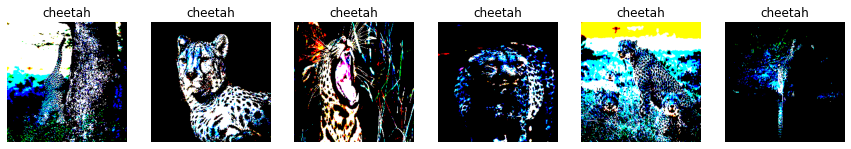

In [8]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load random images from broden

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

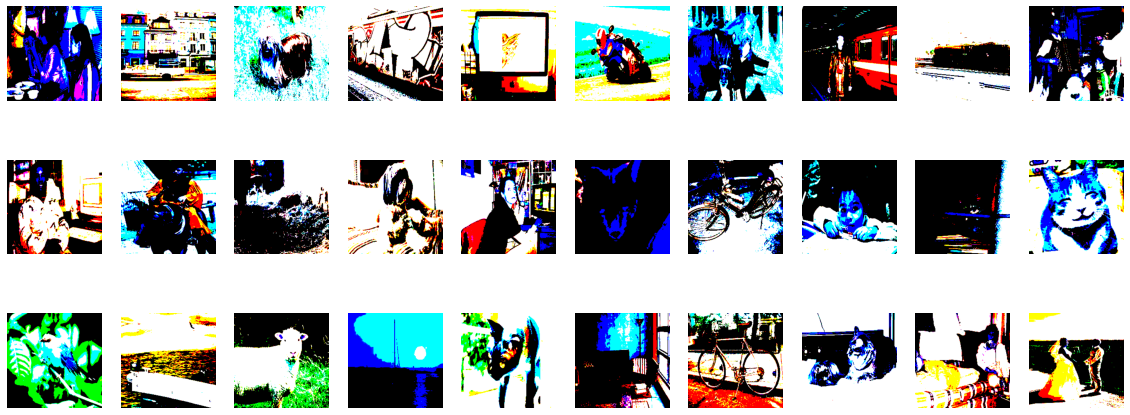

In [9]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Load Concept Images

In [10]:
concepts_folder = CONCEPTS_PATH

concepts_files = os.listdir(concepts_folder)
concepts_availables = np.unique([t for t in concepts_files])
print('The available concepts are : \n', '; '.join(concepts_availables))

def load_concepts(concepts):
    files = glob.glob(CONCEPTS_PATH + concepts + '/*.jpg')
    imgs  = [cv2.imread(img)[...,::-1] for img in files]
    imgs  = [tf.image.resize(img, [img_width, img_height]) for img in imgs]
    imgs = [tf.keras.applications.resnet50.preprocess_input(img) for img in imgs]

    return np.array(imgs)

The available concepts are : 
 chequered; dotted; striped


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: chequered  - shape: (30, 224, 224, 3)


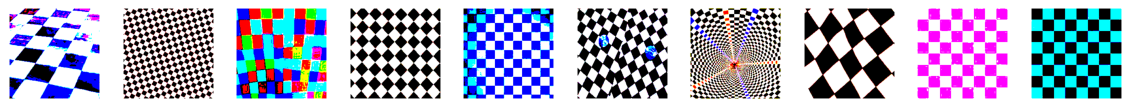

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: dotted  - shape: (30, 224, 224, 3)


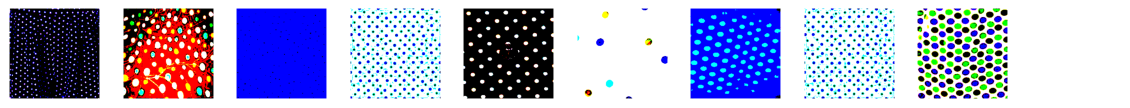

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: striped  - shape: (30, 224, 224, 3)


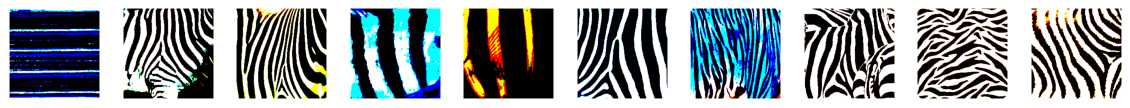

In [11]:
concepts = {concepts: load_concepts(concepts) for concepts in concepts_availables}

plt.rcParams["figure.figsize"] = [20, 8]
for concepts_name, images in concepts.items():
    print(f"\n\nTexture: {concepts_name}  - shape: {images.shape}")
    for i in range(10):
        plt.subplot(1, 10, i+1)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

### Weight Vectors

The class weight vectors are the corresponding weight vectors in the Dense layer.

For the prototypes/concepts, each weight vector is found through logistic regression between the prototype/concept images (positive samples) and random images from the broden dataset (negatives) in the latent space.

In [12]:
# Load ResNet pretrained on ImageNet
model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=True)

In [13]:
# Get (single) Dense layer responsible for predicting all 1000 classes
dense_layer = model.get_layer('predictions')
dense_layer_weights = dense_layer.trainable_weights[0].numpy() # weights at position 0, bias term at position 1
np.shape(dense_layer_weights)

(2048, 1000)

In [14]:
# Only select weight vectors from Dense layer corresponding to the inspected classes
# Note: indexes already zero-based
cls_imagenet_ids = {
    'cheetah': 293,
    'snake': 57,
    'tiger':  292,
    'turtle': 35,
    'zebra':  340
}
# Note: weight vectors are already almost unity vectors
cls_weights = {}
for cls, id in cls_imagenet_ids.items():
    cls_weights[cls] = dense_layer_weights.T[id] #/ np.linalg.norm(dense_layer_weights.T[id], 2)
np.shape(cls_weights['zebra'])

(2048,)

#### Compute weight vectors for every prototype set

In [15]:
# Load only ResNet backbone
backbone = tf.keras.Model(inputs=model.input, outputs=model.get_layer('predictions').input, name='backbone')
# Extract features from random dataset (there are 1000 random samples)
random_features = backbone(random_dataset)
np.shape(random_features)

2024-03-14 19:55:05.974464: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-14 19:55:06.480113: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:55:06.481222: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:55:06.481281: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-14 19:55:06.482491: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:55:06.482588: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


TensorShape([1000, 2048])

In [16]:
# Compute prototype features in latent space (each prototype set has 30 vectors of dimension 2048)
con_features = {}
for con_name, con_imgs in concepts.items():
    con_features[con_name] = backbone(con_imgs)
np.shape(con_features['dotted'])

TensorShape([30, 2048])

In [17]:
# Compute prototype weight vectors via Logistic Regression for multiple partitions of the random set
# For every prototype set, we fit a logistic regressor to recognize the positive samples (the prototype vectors)
# against the negative samples (the random vectors)
num_parts = 30 # how often to randomly select subsets of the random set
con_weights = {}
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( len(random_features), 500, replace = False )

    for con_name, con_f in con_features.items():

        # Build dataset of latent features: concept features are the positive examples, random features are the negatives
        con_rand_set = np.concatenate((con_f, random_features.numpy()[random_ids]))
        con_rand_y = [1]*len(con_f) + [0]*len(random_ids)

        # Fit log. regressor
        clf = LogisticRegression(random_state=0).fit(con_rand_set, con_rand_y)

        # Store normalized centered weight vectors (as in paper, page 6)
        if i == 0: con_weights[con_name] = []
        clf_centered = clf.coef_[0] - np.mean(clf.coef_[0])
        clf_norm = clf_centered / np.linalg.norm(clf_centered)
        con_weights[con_name].append( clf_norm )

np.shape(con_weights['dotted'])

(30, 2048)

#### Get global prototype relevance scores via projections of the class weight vectors on the prototype basis

In [18]:
# Get the list of concepts (for ease of access later)
con_list = list(concepts.keys())

In [19]:
# Build matrix of class weight vectors
# Each row is the weight vector of the Dense layer corresponding to that class
cls_mat = np.asarray(list(cls_weights.values()))
np.shape(cls_mat)

(5, 2048)

In [20]:
# Build matrix of prototype weight vectors
# Each row is the weight vector of the logistic regressor corresponding to that prototype
# Note: in this simple case, there is one prototype set per classes (5 to 5). This will not always be true.
con_tensor = np.asarray(list(con_weights.values()))
np.shape(con_tensor)

(3, 30, 2048)

In [21]:
# Multiply matrices to compute relevance scores per class
# Row i holds the mean relevance scores of class i w.r.t. all the concepts
cls_con_proj = []
for j in range(con_tensor.shape[1]):
    cls_con_proj.append( np.dot(cls_mat, np.linalg.pinv(con_tensor[:,j,:])) )
cls_con_proj = np.mean(cls_con_proj, axis=0) # average out over all the weight vectors of a concept
np.shape(cls_con_proj)

(5, 3)

In [22]:
# It is expected that the prototype with the same name as the class is found as most relevant for that class
for i in range(len(classes)):
    print(classes[i])
    for j in range(len(con_list)):
        print(con_list[j] + ': ' + str(cls_con_proj[i,j]))
    print()

cheetah
chequered: -0.007603561062502812
dotted: 0.10613452672864727
striped: 0.024658953152038268

snake
chequered: -0.021835820849899816
dotted: -0.009408416300260354
striped: 0.020742557279474057

tiger
chequered: -0.10546264206600646
dotted: -0.18909518464096442
striped: 0.28096046957596243

turtle
chequered: -0.0467569857137904
dotted: -0.003384307483081502
striped: -0.050857661455316255

zebra
chequered: -0.05520264073853642
dotted: -0.259495231136387
striped: 0.41818831214520674



In [23]:
# Replace negative scores (that mark irrelevance of that concept) with 0's
cls_con_proj_pos = np.max((cls_con_proj, np.zeros(cls_con_proj.shape)), axis=0)
cls_con_proj_pos

array([[0.        , 0.10613453, 0.02465895],
       [0.        , 0.        , 0.02074256],
       [0.        , 0.        , 0.28096047],
       [0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.41818831]])

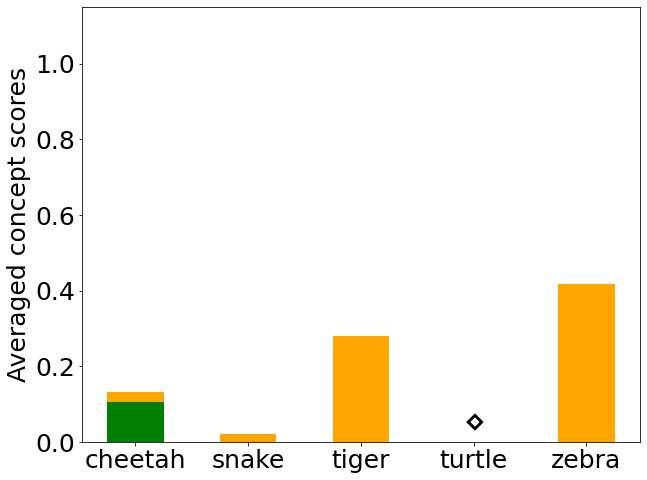

In [24]:
con_colors = ['yellow', 'green', 'orange']
fontsize = 25
fig, ax = plt.subplots(figsize=(10,8))
bottom = np.zeros(len(classes))
for j in range(cls_con_proj_pos.shape[1]):
    rects = plt.bar(classes, cls_con_proj_pos[:,j], width=0.5, label=con_list[j], bottom=bottom, color=con_colors[j])
    bottom += cls_con_proj_pos[:,j]

# Add asterisks for zero-height bars
for rect, b in zip(rects, bottom):
   if b == 0:
       ax.text(rect.get_x() + rect.get_width() / 2,
               0.01,  # Adjust vertical position slightly
               '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color='black')

plt.ylim(0.0, 1.15)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_ibd_broden_stacked.png', bbox_inches='tight')
plt.show()

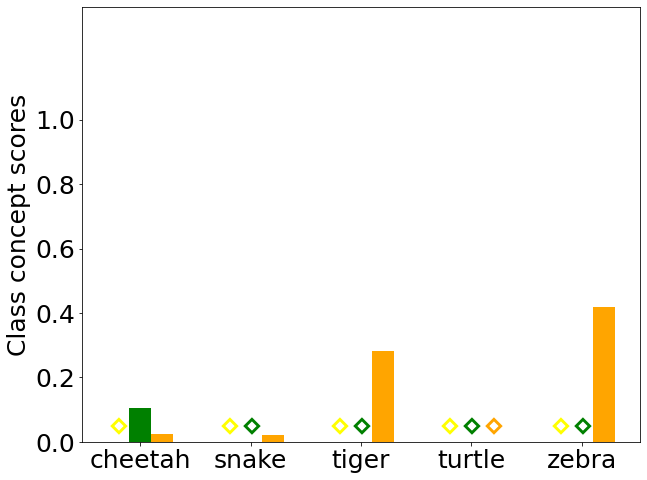

In [25]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i in range(len(cls_con_proj_pos.T)):
   offset = width * multiplier
   rects = plt.bar(x + offset, cls_con_proj_pos[:,i], width, label=con_list[i], color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, cls_con_proj_pos[:,i]):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Class concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_ibd_broden_scores.png', bbox_inches='tight')
plt.show()

#### Get local concept relevance scores via projections of each sample vector on the concept basis

In [26]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
lookup_cls_concepts = [concept_basis[1], # cheetah -> dotted
                       concept_basis[0], # snake -> chequered
                       concept_basis[2], # tiger -> striped
                       concept_basis[0], # turtle -> chequered
                       concept_basis[2]] # zebra -> striped

In [27]:
# Extract features for whole test set
test_features = backbone.predict(test_set.batch(32), verbose=1)
test_features.shape

7/7 [==============================] - 2s 132ms/step


(212, 2048)

In [28]:
# Deactivate Softmax normalization
model.layers[-1].activation = tf.keras.activations.linear
# Store predictions before Softmax layer (needed for normalizing scores to true probabilities)
preds_no_soft = model.predict(test_set.batch(32), verbose=1)
preds_no_soft = preds_no_soft[:, list(cls_imagenet_ids.values())]
preds_no_soft.shape

7/7 [==============================] - 1s 38ms/step


(212, 5)

In [29]:
# Project every test vector onto the prototype matrix
# Row i holds the mean relevance scores of the i-th test sample w.r.t. all the prototypes
test_con_proj = []
for j in range(con_tensor.shape[1]):
    test_con_proj.append( np.dot(test_features, con_tensor[:,j,:].T) )
test_con_proj = np.mean(test_con_proj, axis=0) # average out over all the weight vectors of a concept
np.shape(test_con_proj)

(212, 3)

In [30]:
probs_cls_dict = {}
test_con_proj_cls_avg = []
for c in range(len(classes)):
    test_con_proj_cls = test_con_proj[np.where(y_true_img == c)]
    preds_no_soft_cls = preds_no_soft[np.where(y_true_img == c), c][0][0]

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[c]

    # Concept scores for class c
    s = cls_con_proj_pos[c]

    # Average sample scores divided by w.T*a (Equation 7, page 6)
    test_con_proj_cls_avg.append( np.mean(test_con_proj_cls * s / preds_no_soft_cls, axis=0) )

    bce, cos_sim = [], []
    for p in test_con_proj_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p*s) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), (p*s).reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(test_con_proj_cls),1)), test_con_proj_cls)

    print(classes[c])
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

cheetah
BCE:
1.9496+/-3.5238
Cosine Similarity:
0.7316+/-0.6209
Rank Correlation:
0.6507936507936508

snake
BCE:
11.5302+/-0.0229
Cosine Similarity:
0.0+/-0.0
Rank Correlation:
0.6216216216216216

tiger
BCE:
0.3495+/-1.7276
Cosine Similarity:
0.9535+/-0.3014
Rank Correlation:
0.9728682170542636

turtle
BCE:
11.5129+/-0.0
Cosine Similarity:
0.0+/-0.0
Rank Correlation:
0.5357142857142856

zebra
BCE:
0.0+/-0.0
Cosine Similarity:
1.0+/-0.0
Rank Correlation:
1.0



In [31]:
# Replace scores slightly below 0 (due to rounding errors) with 0's
test_con_proj_cls_avg = np.asarray(test_con_proj_cls_avg)
test_con_proj_cls_avg_pos = np.max((test_con_proj_cls_avg, np.zeros(test_con_proj_cls_avg.shape)), axis=0)
test_con_proj_cls_avg_pos

array([[0.        , 0.00909548, 0.00214327],
       [0.        , 0.        , 0.00457126],
       [0.        , 0.        , 0.05534291],
       [0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.2746593 ]])

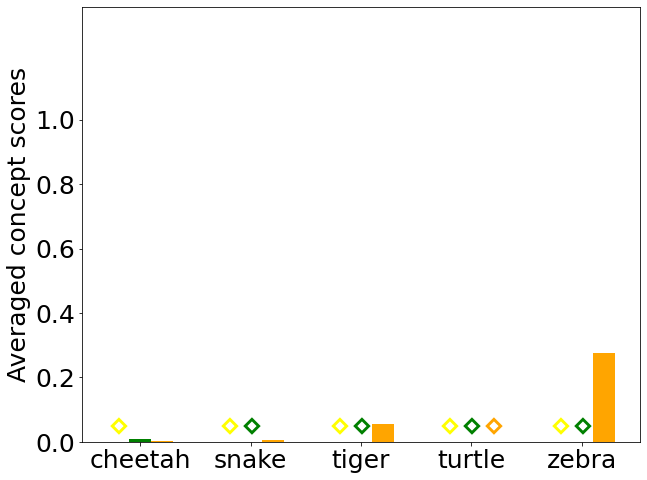

In [32]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i in range(len(test_con_proj_cls_avg_pos.T)):
   offset = width * multiplier
   rects = plt.bar(x + offset, test_con_proj_cls_avg_pos[:,i], width, label=con_list[i], color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, test_con_proj_cls_avg_pos[:,i]):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_ibd_broden.png', bbox_inches='tight')
plt.show()

In [33]:
# Count how often each prototype was found as most relevant for each class
cls_con_freq = {}
for i in range(len(classes)):
    rel_con_inds = np.argmax(test_con_proj[np.where(y_true_img == i)], axis=1)
    freq = np.asarray([np.count_nonzero(rel_con_inds == j) for j in range(len(con_list))]) / len(rel_con_inds)
    cls_con_freq[classes[i]] = freq
cls_con_freq

{'cheetah': array([0.19047619, 0.38095238, 0.42857143]),
 'snake': array([0.27027027, 0.        , 0.72972973]),
 'tiger': array([0.        , 0.04651163, 0.95348837]),
 'turtle': array([0.16666667, 0.26190476, 0.57142857]),
 'zebra': array([0., 0., 1.])}

In [34]:
# Invert dictionary (for plotting purposes)
con_cls_freq = {}
for c in con_list:
    con_cls_freq[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        con_cls_freq[c][i] = cls_con_freq[classes[i]][con_list.index(c)]
con_cls_freq

{'chequered': array([0.19047619, 0.27027027, 0.        , 0.16666667, 0.        ]),
 'dotted': array([0.38095238, 0.        , 0.04651163, 0.26190476, 0.        ]),
 'striped': array([0.42857143, 0.72972973, 0.95348837, 0.57142857, 1.        ])}

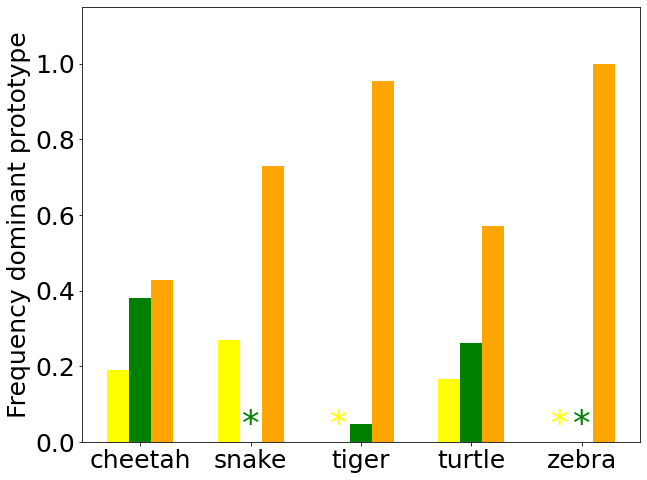

In [35]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(con_cls_freq.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.15)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
#plt.legend([c[:-4] for c in concepts], loc='upper right',
#           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/imagenet_ibd_freq_broden.png', bbox_inches='tight')
plt.show()